## <U>Etapa 1</U>: Cargar bibliotecas e inspeccion general

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Biblitecas importadas correctamente")

Biblitecas importadas correctamente


In [11]:
df_indicadores = pd.read_csv("../Datos/Raw/indicadores_educativos_jujuy_2025.csv", sep=";", decimal=",")
print("Dataset cargado correctamente")

Dataset cargado correctamente


### Inspeccion registros

In [12]:
print("Dimensiones: ",df_indicadores.shape)

display(df_indicadores.head())

df_indicadores.info()

Dimensiones:  (48, 7)


,Anio,Nivel,Jurisdiccion,Departamento,Metrica,Valor,Unidad
0,2025,Secundaria,Jujuy,COCHINOCA,Sobreedad,21.99,%
1,2025,Secundaria,Jujuy,EL CARMEN,Sobreedad,21.79,%
2,2025,Secundaria,Jujuy,DOCTOR MANUEL BELGRANO,Sobreedad,22.92,%
3,2025,Secundaria,Jujuy,HUMAHUACA,Sobreedad,28.92,%
4,2025,Secundaria,Jujuy,LEDESMA,Sobreedad,23.6,%


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Anio          48 non-null     int64 
 1   Nivel         48 non-null     object
 2   Jurisdiccion  48 non-null     object
 3   Departamento  48 non-null     object
 4   Metrica       48 non-null     object
 5   Valor         48 non-null     object
 6   Unidad        48 non-null     object
dtypes: int64(1), object(6)
memory usage: 2.8+ KB


### Verificar calidad

In [19]:
print("Valores nulos: ")
display(df_indicadores.isnull().sum())

print("\nDuplicados",
      df_indicadores.duplicated().sum())

print("\nDepartamentos: ")
display(df_indicadores["Departamento"].nunique())

Valores nulos: 


Anio            0
Nivel           0
Jurisdiccion    0
Departamento    0
Metrica         0
Valor           0
Unidad          0
dtype: int64


Duplicados 0

Departamentos: 


16

### Tipos de indicadores


In [23]:
print("Tipos de indicadores: ")
display(df_indicadores["Metrica"].value_counts())

print("\nValores originales: ")
display(df_indicadores["Valor"].map(repr).head(15))

print("\nTipo de dato de Valor: ")
print(df_indicadores["Valor"].dtype)

Tipos de indicadores: 


Metrica
Sobreedad     16
Egresados     16
Repitencia    16
Name: count, dtype: int64


Valores originales: 


0     '21.99'
1     '21.79'
2     '22.92'
3     '28.92'
4      '23.6'
5     '19.23'
6     '16.87'
7     '35.54'
8      '17.4'
9     '20.17'
10    '33.82'
11    '15.73'
12    '21.33'
13    '26.61'
14    '18.43'
Name: Valor, dtype: object


Tipo de dato de Valor: 
object


In [24]:
display(df_indicadores["Departamento"].value_counts().sort_index())

Departamento
COCHINOCA                 3
DOCTOR MANUEL BELGRANO    3
EL CARMEN                 3
HUMAHUACA                 3
LEDESMA                   3
PALPALA                   3
RINCONADA                 3
SAN ANTONIO               3
SAN PEDRO                 3
SANTA BARBARA             3
SANTA CATALINA            3
SUSQUES                   3
TILCARA                   3
TUMBAYA                   3
VALLE GRANDE              3
YAVI                      3
Name: count, dtype: int64

### Convertir valor a numerico

In [27]:
df_indicadores["Valor"] = pd.to_numeric(df_indicadores["Valor"], errors = "raise")
print("Valores convertidos correctamente")

Valores convertidos correctamente


### Comprobar la conversion

In [29]:
print("Tipo de datos: ",df_indicadores["Valor"].dtype)

display(df_indicadores["Valor"].describe().round(2))

Tipo de datos:  float64


count      48.00
mean      165.53
std       477.01
min         2.41
25%         9.29
50%        21.89
75%        41.00
max      3007.00
Name: Valor, dtype: float64

In [30]:
display(
    df_indicadores.groupby("Metrica")["Valor"].agg(["mean","median","min","max","std"]).round(2)
)

,mean,median,min,max,std
Metrica,,,,,
Egresados,465.50,163.50,23.00,3007.00,754.20
Repitencia,7.84,7.68,2.41,16.38,3.15
Sobreedad,23.24,21.89,15.73,35.54,5.85


### Verificar que son cada registros (%,personas)

In [36]:
display(
    df_indicadores.groupby(["Metrica","Unidad"])
        .agg(
            registros= ("Valor","count"),
            promedio=("Valor","mean"),
            minimo=("Valor","min"),
            maximo=("Valor","max")
        ).round(2)
)

,,registros,promedio,minimo,maximo
Metrica,Unidad,,,,
Egresados,personas,16,465.50,23.00,3007.00
Repitencia,%,16,7.84,2.41,16.38
Sobreedad,%,16,23.24,15.73,35.54


In [37]:
display(
    df_indicadores[
        df_indicadores["Metrica"]== "Egresados"
    ].sort_values("Valor",ascending=False)
)

,Anio,Nivel,Jurisdiccion,Departamento,Metrica,Valor,Unidad
18,2025,Secundaria,Jujuy,DOCTOR MANUEL BELGRANO,Egresados,3007.0,personas
17,2025,Secundaria,Jujuy,EL CARMEN,Egresados,975.0,personas
20,2025,Secundaria,Jujuy,LEDESMA,Egresados,883.0,personas
24,2025,Secundaria,Jujuy,SAN PEDRO,Egresados,883.0,personas
21,2025,Secundaria,Jujuy,PALPALA,Egresados,456.0,personas
31,2025,Secundaria,Jujuy,YAVI,Egresados,287.0,personas
28,2025,Secundaria,Jujuy,TILCARA,Egresados,272.0,personas
19,2025,Secundaria,Jujuy,HUMAHUACA,Egresados,179.0,personas
16,2025,Secundaria,Jujuy,COCHINOCA,Egresados,148.0,personas
25,2025,Secundaria,Jujuy,SANTA BARBARA,Egresados,144.0,personas


### Comparando departamentos

In [38]:
tabla_departamentos = df_indicadores.pivot(index="Departamento",columns="Metrica",values="Valor")

display(tabla_departamentos)

Metrica,Egresados,Repitencia,Sobreedad
Departamento,,,
COCHINOCA,148.0,5.44,21.99
DOCTOR MANUEL BELGRANO,3007.0,7.67,22.92
EL CARMEN,975.0,8.40,21.79
HUMAHUACA,179.0,9.24,28.92
LEDESMA,883.0,6.53,23.60
PALPALA,456.0,7.70,19.23
RINCONADA,27.0,2.41,16.87
SAN ANTONIO,40.0,16.38,35.54
SAN PEDRO,883.0,6.64,17.40


## <U>Etapa 2</u>: Graficos

### Sobreedad por departamento

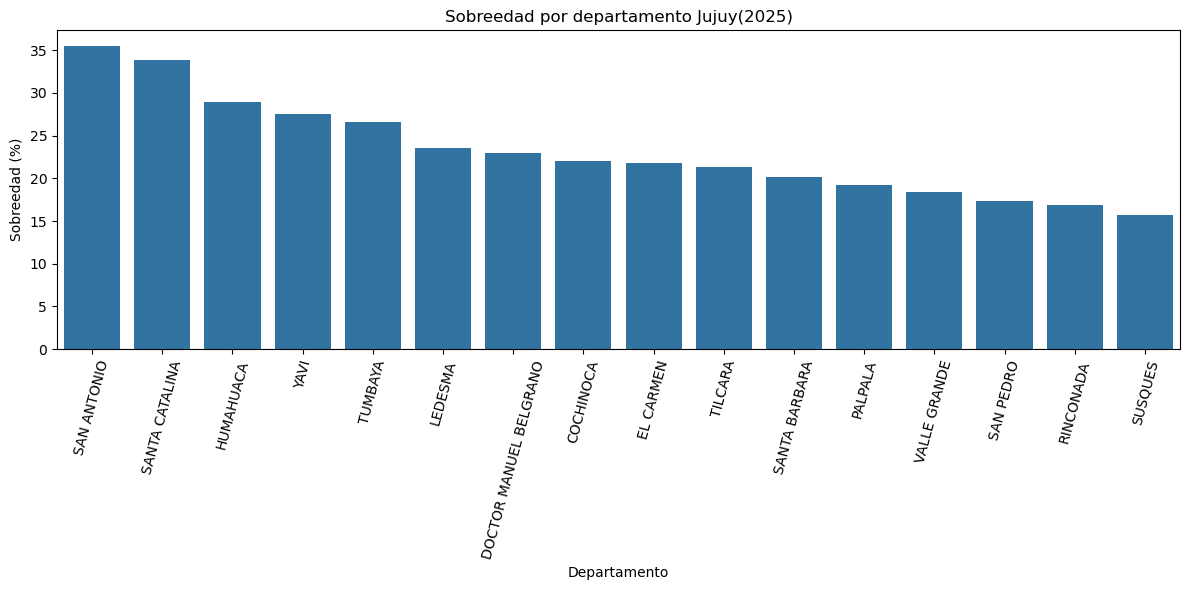

In [40]:
sobreedad=tabla_departamentos.sort_values(by="Sobreedad",ascending=False)

plt.figure(figsize=(12,6))

sns.barplot(
    data = sobreedad.reset_index(),
    x = "Departamento",
    y = "Sobreedad"
)

plt.title("Sobreedad por departamento Jujuy(2025)")
plt.xlabel("Departamento")
plt.ylabel("Sobreedad (%)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

### Repitencia por departamento

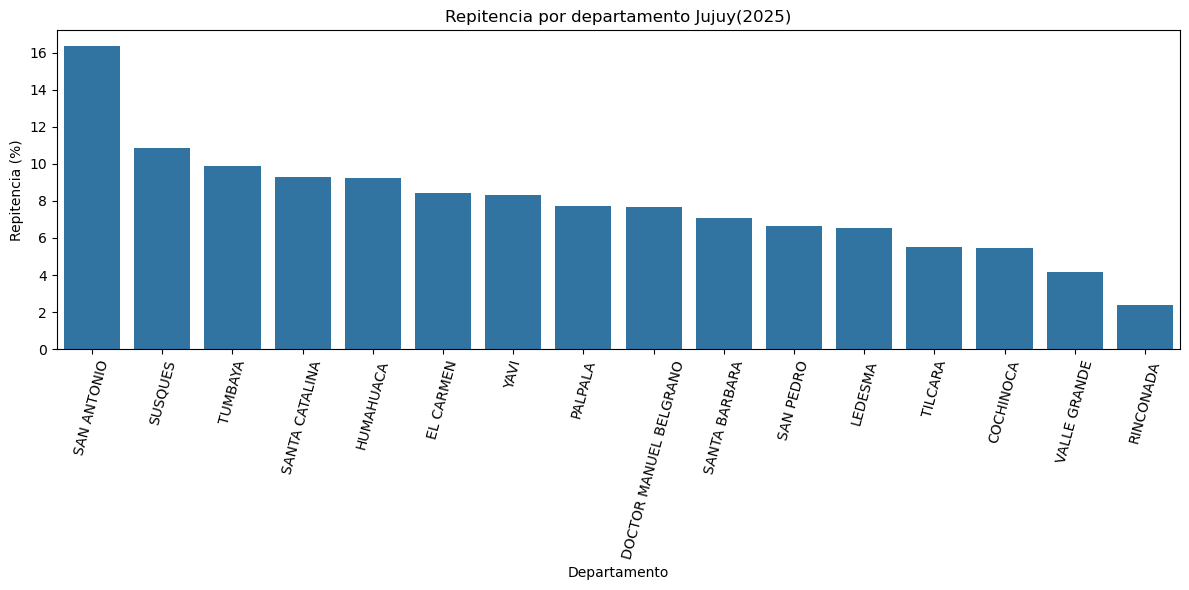

In [41]:
repitencia=tabla_departamentos.sort_values(by="Repitencia",ascending=False)

plt.figure(figsize=(12,6))

sns.barplot(
    data = repitencia.reset_index(),
    x = "Departamento",
    y = "Repitencia"
)

plt.title("Repitencia por departamento Jujuy(2025)")
plt.xlabel("Departamento")
plt.ylabel("Repitencia (%)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

### Egresados por departamento

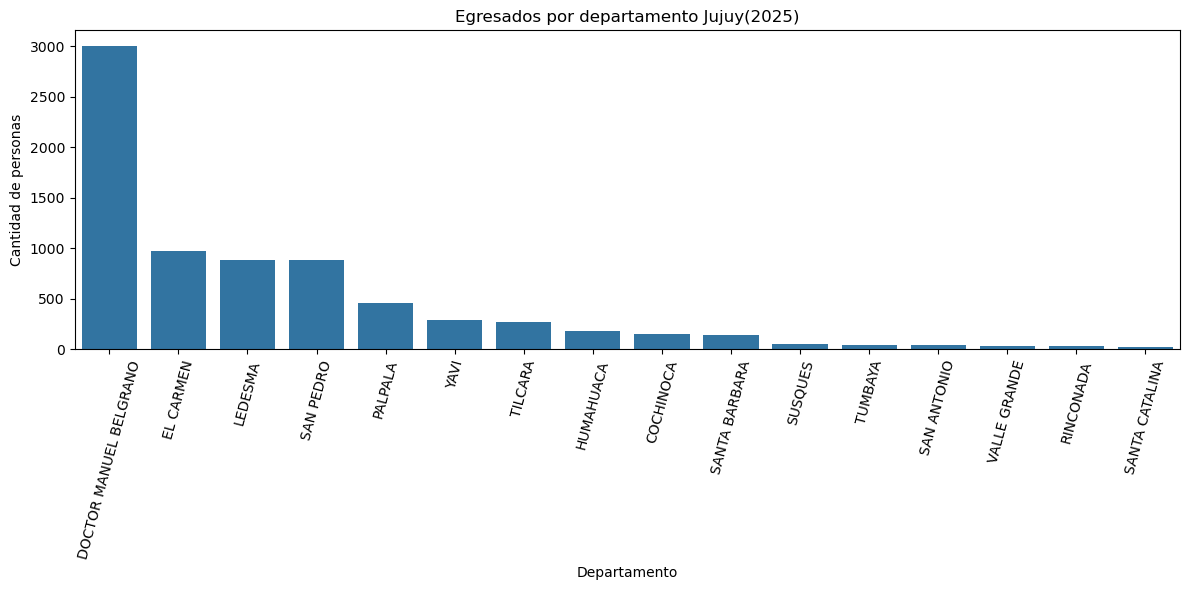

In [42]:
egresados=tabla_departamentos.sort_values(by="Egresados",ascending=False)

plt.figure(figsize=(12,6))

sns.barplot(
    data = egresados.reset_index(),
    x = "Departamento",
    y = "Egresados"
)

plt.title("Egresados por departamento Jujuy(2025)")
plt.xlabel("Departamento")
plt.ylabel("Cantidad de personas")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

# Conclusiones del EDA de indicadores educativos

### El analisis exploratorio permitio identificar diferencias territoriales en tres indicadores educativos del nivel secundario de la provincia de Jujuy durante 2025: sobreedad, repitencia y cantidad de egresados.
### Se observaron variaciones importantes entre departamentos. San Antonio presento los porcentajes mas relevantes de sobreedad y repitencia, mientras que Doctor Manuel Belgrano registro la mayor cantidad de egresados.
### Los indicadores permiten contextualizar la situacion educativa de los departamentos, pero no explican por si solos las causas de las diferencias observadas ni representan el rendimiento individual de los estudiantes.
### <U>Limitaciones:</U> el conjunto de datos contiene informacion agregada por departamento y corresponde a un unico año. No permite realizar analisis individuales ni establecer tendencias temporales.
### <U>Decision para el proyecto:</U> estos indicadores se conservaran como informacion contextual territorial. No se utilizaran como variables para calcular la afinidad vocacional de los perfiles individuales.